In [1]:
# Import necessary libraries

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTENC , RandomOverSampler 
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score , confusion_matrix, classification_report , recall_score , precision_score, f1_score
import os
import joblib




In [2]:
# Load the dataset
df = pd.read_csv('dataset.csv')


print("Dataset shape:", df.shape)
print("First few rows of the dataset:")
print(df.head())

Dataset shape: (43400, 12)
First few rows of the dataset:
      id  gender   age  hypertension  heart_disease ever_married  \
0  30669    Male   3.0             0              0           No   
1  30468    Male  58.0             1              0          Yes   
2  16523  Female   8.0             0              0           No   
3  56543  Female  70.0             0              0          Yes   
4  46136    Male  14.0             0              0           No   

      work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0      children          Rural              95.12  18.0              NaN   
1       Private          Urban              87.96  39.2     never smoked   
2       Private          Urban             110.89  17.6              NaN   
3       Private          Rural              69.04  35.9  formerly smoked   
4  Never_worked          Rural             161.28  19.1              NaN   

   stroke  
0       0  
1       0  
2       0  
3       0  
4       0  


In [3]:
# data information
print("Dataset information:")
print(df.info())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43400 entries, 0 to 43399
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 43400 non-null  int64  
 1   gender             43400 non-null  object 
 2   age                43400 non-null  float64
 3   hypertension       43400 non-null  int64  
 4   heart_disease      43400 non-null  int64  
 5   ever_married       43400 non-null  object 
 6   work_type          43400 non-null  object 
 7   Residence_type     43400 non-null  object 
 8   avg_glucose_level  43400 non-null  float64
 9   bmi                41938 non-null  float64
 10  smoking_status     30108 non-null  object 
 11  stroke             43400 non-null  int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 4.0+ MB
None


In [4]:
#check duplicated rows

print(df.duplicated().sum())

# remove id column
df.drop('id', axis=1, inplace=True)

0


<Axes: title={'center': 'Stroke Class Distribution'}, xlabel='stroke'>

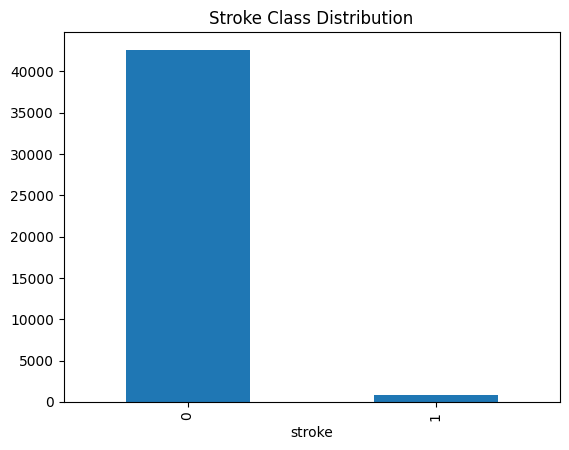

In [5]:
#check imbalance dataset

df['stroke'].value_counts().plot(kind='bar', title='Stroke Class Distribution')


In [6]:
# check missing values in each column
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values)


Missing values in each column:
gender                   0
age                      0
hypertension             0
heart_disease            0
ever_married             0
work_type                0
Residence_type           0
avg_glucose_level        0
bmi                   1462
smoking_status       13292
stroke                   0
dtype: int64


In [7]:
# handle missing values

df['bmi'] = df['bmi'].fillna(df['bmi'].mean())
df['smoking_status'] = df['smoking_status'].fillna('Unknown')


In [8]:
# display dataset after handling missing values
print("Dataset after handling missing values:")
df.isnull().sum()

Dataset after handling missing values:


gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [9]:
categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

# Apply label encoding to categorical columns

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

print(df.dtypes)

gender                 int64
age                  float64
hypertension           int64
heart_disease          int64
ever_married           int64
work_type              int64
Residence_type         int64
avg_glucose_level    float64
bmi                  float64
smoking_status         int64
stroke                 int64
dtype: object


In [10]:
# separate features and target variable
X = df.drop('stroke', axis=1)
y = df['stroke']


In [11]:
# split dataset

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 , stratify=y)

In [12]:
smotenc_categorical_columns = [
    'gender',
    'hypertension',
    'heart_disease',
    'ever_married',
    'work_type',
    'Residence_type',  
    'smoking_status'    
]

categorical_indices = [
    X_train.columns.get_loc(column)
    for column in smotenc_categorical_columns
]


In [13]:
# apply random over sampling

random_over = RandomOverSampler(
    sampling_strategy=0.10,
    random_state=42
)

X_after_over , y_after_over = random_over.fit_resample(X_train , y_train)

In [14]:
#apply SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.50,
    random_state=42,
    k_neighbors=5
) 

X_after_smote , y_after_smote = smotenc.fit_resample(X_train , y_train)


In [15]:
# apply random under sampling

random_under = RandomUnderSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_final , y_train_final = random_under.fit_resample(X_after_smote , y_after_smote)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
x_test_scaled = scaler.transform(X_test)

In [17]:
# apply logistic regression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight='balanced'
)

logistic_model.fit(X_train_scaled, y_train_final)

y_pred_logistic = logistic_model.predict(x_test_scaled)



In [18]:
# evaluate logistic regression model
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
confusion_logistic = confusion_matrix(y_test, y_pred_logistic)
recall_score_logistic = recall_score(y_test, y_pred_logistic)
precision_score_logistic = precision_score(y_test, y_pred_logistic)
f1_score_logistic = f1_score(y_test, y_pred_logistic)

print("Logistic Regression Model Evaluation:")
print(f'Accuracy: {accuracy_logistic:.2f}')
print(f'Confusion Matrix:\n{confusion_logistic}')
print(f'Recall: {recall_score_logistic:.2f}')
print(f'Precision: {precision_score_logistic:.2f}')
print(f'F1-Score: {f1_score_logistic:.2f}')
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Model Evaluation:
Accuracy: 0.74
Confusion Matrix:
[[6292 2231]
 [  39  118]]
Recall: 0.75
Precision: 0.05
F1-Score: 0.09
              precision    recall  f1-score   support

           0       0.99      0.74      0.85      8523
           1       0.05      0.75      0.09       157

    accuracy                           0.74      8680
   macro avg       0.52      0.74      0.47      8680
weighted avg       0.98      0.74      0.83      8680



In [19]:
# calculation logistic regression result

logistic_metric = {
    'Accuracy' : accuracy_score(
        y_test,
        y_pred_logistic
    ),

    'Precision': precision_score(
        y_test,
        y_pred_logistic,
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_logistic,
        zero_division=0
    ),

    'F1_score': f1_score(
        y_test,
        y_pred_logistic,
        zero_division=0
    )
}

logistic_confusion_matrix = confusion_matrix(
    y_test,
    y_pred_logistic
)

logistic_report = classification_report(
    y_test,
    y_pred_logistic,
    target_names=['No Stroke' , 'Stroke'],
    output_dict=True,
    zero_division=0
)

# create a models folder 
os.makedirs('models' , exist_ok=True)

model_bundle = {
    'model': logistic_model,
    'scaler': scaler,
    'label_encoders': label_encoders,
    'feature_columns': list(X.columns),
    'confusion_matrix': logistic_confusion_matrix,
    'classification_report' : logistic_report
}

joblib.dump(
    model_bundle,
    "models/logistic_stroke_model1.joblib"
)




['models/logistic_stroke_model1.joblib']

In [20]:
# apply SVM

svm_model = SVC(
    max_iter=100,
    random_state=42,
    class_weight='balanced'
)

svm_model.fit(X_train_scaled, y_train_final)

y_pred_svm = svm_model.predict(X_test)


c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


In [21]:
# evaluate svm model

accuracy_svm = accuracy_score(y_test, y_pred_svm)
confusion_svm = confusion_matrix(y_test, y_pred_svm)
recall_score_svm = recall_score(y_test, y_pred_svm)
precision_score_svm = precision_score(y_test, y_pred_svm)
f1_score_svm = f1_score(y_test, y_pred_svm)

print("SVM Model Evaluation:")
print(f'Accuracy: {accuracy_svm:.2f}')
print(f'Confusion Matrix:\n{confusion_svm}')
print(f'Recall: {recall_score_svm:.2f}')
print(f'Precision: {precision_score_svm:.2f}')
print(f'F1-Score: {f1_score_svm:.2f}')
print(classification_report(y_test, y_pred_svm))

SVM Model Evaluation:
Accuracy: 0.98
Confusion Matrix:
[[8523    0]
 [ 157    0]]
Recall: 0.00
Precision: 0.00
F1-Score: 0.00
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      8523
           1       0.00      0.00      0.00       157

    accuracy                           0.98      8680
   macro avg       0.49      0.50      0.50      8680
weighted avg       0.96      0.98      0.97      8680



c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier

In [22]:
# xgboost model

xgb_model = XGBClassifier(
    random_state=42
)

xgb_model.fit(X_train_scaled, y_train_final)
y_pred_xgb = xgb_model.predict(X_test)

In [23]:
# evaluate xgboost model

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
confusion_xgb = confusion_matrix(y_test, y_pred_xgb)
recall_score_xgb = recall_score(y_test, y_pred_xgb)
precision_score_xgb = precision_score(y_test, y_pred_xgb)
f1_score_xgb = f1_score(y_test, y_pred_xgb)

print("XGBoost Model Evaluation:")
print(f'Accuracy: {accuracy_xgb:.2f}')
print(f'Confusion Matrix:\n{confusion_xgb}')
print(f'Recall: {recall_score_xgb:.2f}')
print(f'Precision: {precision_score_xgb:.2f}')
print(f'F1-Score: {f1_score_xgb:.2f}')
print(classification_report(y_test, y_pred_xgb))


XGBoost Model Evaluation:
Accuracy: 0.98
Confusion Matrix:
[[8523    0]
 [ 157    0]]
Recall: 0.00
Precision: 0.00
F1-Score: 0.00
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      8523
           1       0.00      0.00      0.00       157

    accuracy                           0.98      8680
   macro avg       0.49      0.50      0.50      8680
weighted avg       0.96      0.98      0.97      8680



c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MSI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier

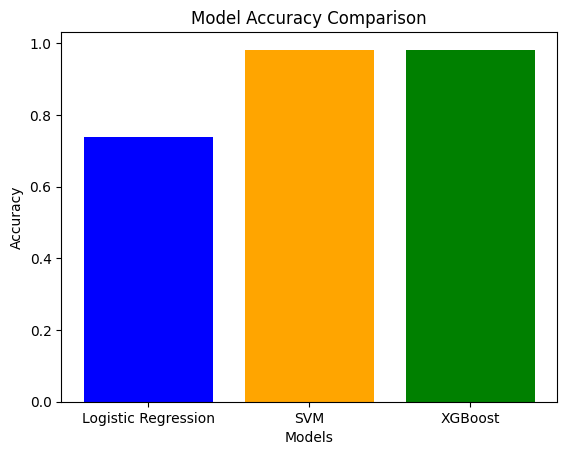

In [24]:
# compare model performance

models = ['Logistic Regression', 'SVM', 'XGBoost']
accuracies = [accuracy_logistic, accuracy_svm, accuracy_xgb ]

plt.bar(models, accuracies , color=['blue', 'orange', 'green' , 'yellow'])
plt.title('Model Accuracy Comparison') 
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.show()
